### Q1. Dataset Loading
Load the Diabetes Dataset using Scikit-learn and display the first 10 records, dataset shape, feature names, and target variable.

In [1]:
import pandas as pd
path = r"https://raw.githubusercontent.com/sakshichaudhari30/Datasets/refs/heads/main/diabetes.csv"
df = pd.read_csv(path)
df.head(10)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


In [3]:
df.shape

(768, 9)

In [4]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='str')

In [5]:
df.Outcome

0      1
1      0
2      1
3      0
4      1
      ..
763    0
764    0
765    0
766    1
767    0
Name: Outcome, Length: 768, dtype: int64

### Q2. Exploratory Data Analysis (EDA)
Perform Exploratory Data Analysis (EDA) by:
- Checking data types
- Identifying missing values
- Displaying statistical summary
- Finding duplicate records

In [6]:
df.dtypes

Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

In [7]:
# missing value 
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [8]:
# statistical summary
df.describe

<bound method NDFrame.describe of      Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0              6      148             72             35        0  33.6   
1              1       85             66             29        0  26.6   
2              8      183             64              0        0  23.3   
3              1       89             66             23       94  28.1   
4              0      137             40             35      168  43.1   
..           ...      ...            ...            ...      ...   ...   
763           10      101             76             48      180  32.9   
764            2      122             70             27        0  36.8   
765            5      121             72             23      112  26.2   
766            1      126             60              0        0  30.1   
767            1       93             70             31        0  30.4   

     DiabetesPedigreeFunction  Age  Outcome  
0                       0.627  

In [9]:
# Duplicate records 
df.duplicated().sum()

np.int64(0)

### Qu.3  Create the following visualizations:

- Histogram of the target variable
- Correlation Heatmap
- Scatter Plot between the most important feature and the target variable
- Box Plot to identify outliers
Write your observations for each visualization.

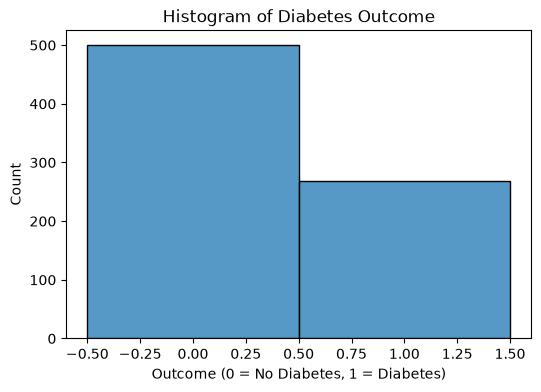

In [10]:
# Histogram
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.histplot(data=df, x="Outcome", discrete=True)
plt.title("Histogram of Diabetes Outcome")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Count")
plt.show()

- Outcome 0 (No diabetes) has more records.
- Outcome 1 (Diabetes) has fewer records.
- The dataset is imbalanced.
- The imbalance may affect model prediction performance.

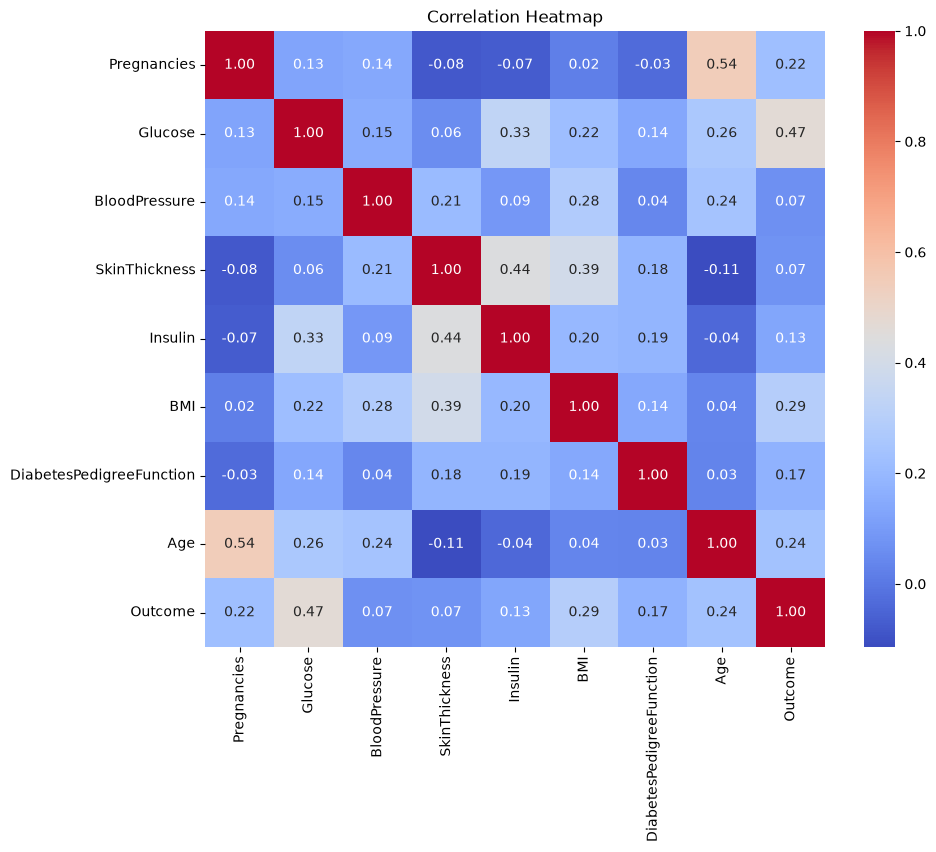

In [11]:
# correlation
plt.figure(figsize=(10, 8))
corr = df.corr(numeric_only=True)

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

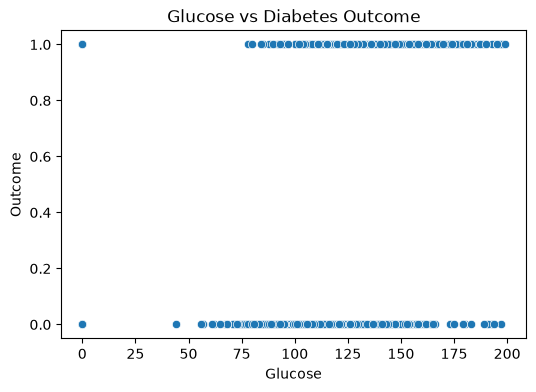

In [12]:
# Scatter plot
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x="Glucose", y="Outcome")
plt.title("Glucose vs Diabetes Outcome")
plt.xlabel("Glucose")
plt.ylabel("Outcome")
plt.show() 

- People with diabetes generally have higher glucose levels.
- Glucose may help predict diabetes, but it cannot predict diabetes perfectly on its own

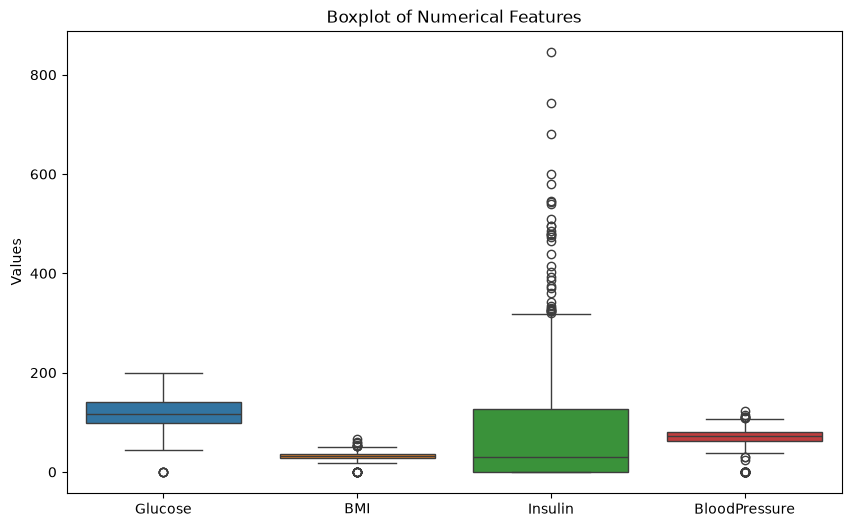

In [13]:
# Boxplot
plt.figure(figsize=(10, 6))

sns.boxplot(data=df[["Glucose", "BMI", "Insulin", "BloodPressure"]])

plt.title("Boxplot of Numerical Features")
plt.ylabel("Values")
plt.show()

- Glucose: Most values are between 100 and 140, with some unusually low values near zero.
- BMI: Most values are between 25 and 40, with a few potential outliers.
- Insulin: Shows a wide spread with many high-value outliers.
- BloodPressure: Most values are between 60 and 85, with some unusually high and low values.

### Q4. Data Preprocessing
Prepare the dataset by:
- Separating features (X) and target (y)
- Splitting the data into 80% training and 20% testing sets using random_state=42
- Explain whether feature scaling is required for a Decision Tree Regressor.

In [14]:
# Separate X and Y feature 
x = df.drop(columns=['Outcome'])
y = df[['Outcome']]

In [15]:
# Splitting the data into 80% training and 20% testing
from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest = train_test_split(x,y,train_size=0.2,random_state=42)
print(xtrain.shape)
print(xtest.shape)

(153, 8)
(615, 8)


In [ ]:
# Feature scaling Required for decision tree

### Q5. Model Training
Build a Decision Tree Regressor using the training dataset and:
- Train the model
- Display the tree depth
- Display the number of leaf nodes
- Visualize the Decision Tree

In [34]:
# Train the model 
from sklearn.tree import DecisionTreeRegressor, plot_tree
import matplotlib.pyplot as plt

model1 = DecisionTreeRegressor(random_state=42)
model1.fit(xtrain, ytrain)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with

In [35]:
# Depth of tree

print("Tree Depth:", model1.get_depth())

Tree Depth: 9


In [36]:
# Leaf Nodes
print("Number of Leaf Nodes:", model1.get_n_leaves())

Number of Leaf Nodes: 32


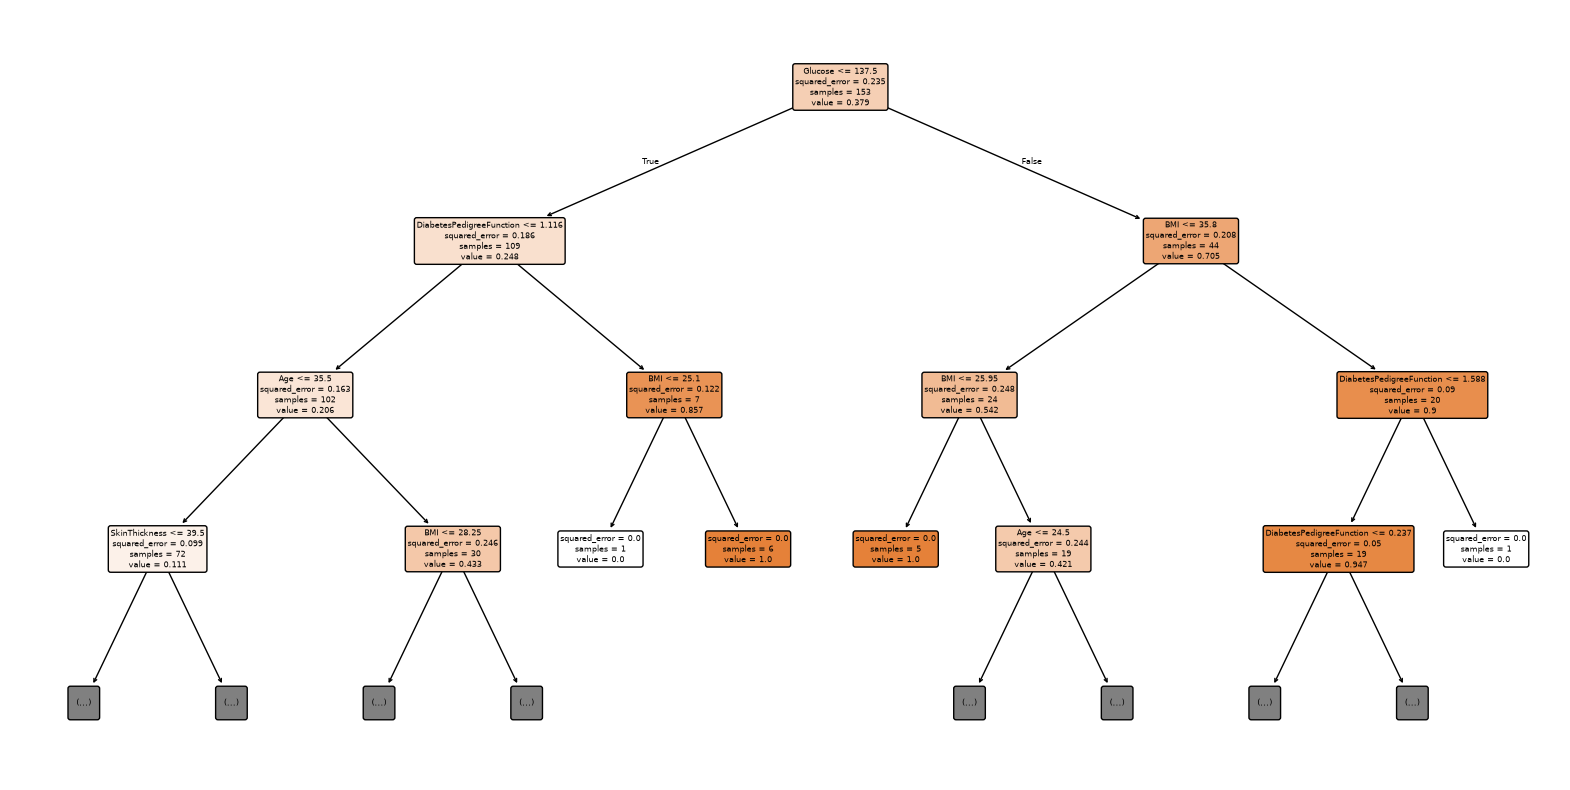

In [38]:
# Tree Visualization
plt.figure(figsize=(20, 10))
plot_tree(model1, feature_names=x.columns, filled=True, rounded=True, max_depth=3)
plt.show()

### Q6. Prediction
Predict the target values for the testing dataset and display a comparison of the Actual and Predicted values.

In [41]:
# Predict target values
y_pred = model1.predict(xtest)

comparison = pd.DataFrame({
    "Actual": ytest.to_numpy().ravel(),
    "Predicted": y_pred.ravel()
})

print(comparison.head(10))

   Actual  Predicted
0       0        1.0
1       0        0.0
2       0        0.0
3       0        1.0
4       0        1.0
5       0        0.0
6       0        0.0
7       0        1.0
8       0        1.0
9       0        1.0


### Q7. Model Evaluation
Evaluate the model using:

- Mean Absolute Error (MAE)
- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)
- R² Score
Interpret the results.

In [42]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(ytest, y_pred)
mse = mean_squared_error(ytest, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(ytest, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)


MAE: 0.35121951219512193
MSE: 0.35121951219512193
RMSE: 0.5926377579897537
R2 Score: -0.5619047619047621


### Qu8 .Feature Importance
Display the feature importance scores and identify the top five most important features. Explain how these features influence the prediction.

In [44]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    "Feature": x.columns,
    "Importance": model1.feature_importances_
})

importance = importance.sort_values(
    by="Importance", ascending=False
)

print(importance)

                    Feature  Importance
5                       BMI    0.264192
6  DiabetesPedigreeFunction    0.238796
1                   Glucose    0.238736
7                       Age    0.085995
0               Pregnancies    0.062797
2             BloodPressure    0.055535
3             SkinThickness    0.053949
4                   Insulin    0.000000


In [45]:
top5 = importance.head(5)
print(top5)

                    Feature  Importance
5                       BMI    0.264192
6  DiabetesPedigreeFunction    0.238796
1                   Glucose    0.238736
7                       Age    0.085995
0               Pregnancies    0.062797


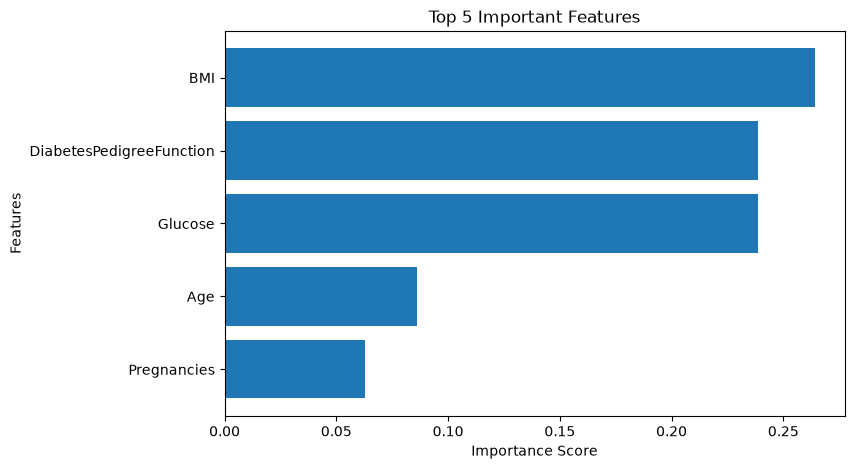

In [46]:
plt.figure(figsize=(8, 5))

plt.barh(top5["Feature"], top5["Importance"])
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Top 5 Important Features")
plt.gca().invert_yaxis()
plt.show()

### Q9. Hyperparameter Tuning

Train another Decision Tree Regressor by changing parameters such as:

- max_depth
- min_samples_split
- min_samples_leaf
Compare the performance of both models and discuss the results.

In [47]:
from sklearn.tree import DecisionTreeRegressor

model2 = DecisionTreeRegressor(
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

model2.fit(xtrain, ytrain)

y_pred2 = model2.predict(xtest)

In [48]:
#comare both models 

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

results = []

for name, pred in [
    ("Original Model", y_pred),
    ("Tuned Model", y_pred2)
]:
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(ytest, pred),
        "MSE": mean_squared_error(ytest, pred),
        "RMSE": np.sqrt(mean_squared_error(ytest, pred)),
        "R2 Score": r2_score(ytest, pred)
    })

results_df = pd.DataFrame(results)
print(results_df)

            Model       MAE      MSE      RMSE  R2 Score
0  Original Model  0.351220  0.35122  0.592638 -0.561905
1     Tuned Model  0.335721  0.24140  0.491325 -0.073527


### Q10. Conclusion

Write a short report that includes:

Overall model performance
Advantages and limitations of Decision Tree Regression
Overfitting analysis
Two real-world applications of Decision Tree Regression



**1. Overall Model Performance:**  
The tuned model performed better than the original model, with lower errors and an improved R² score. However, its performance still needs improvement.

**2. Advantages and Limitations:**  
- Advantages: Easy to understand, visualize, and use.
- Limitations: Can overfit and may perform poorly on new data.

**3. Overfitting Analysis:**  
Tuning parameters like `max_depth` and `min_samples_leaf` helps reduce overfitting. Comparing training and testing performance can help identify it.

**4. Real-World Applications:**  
- Predicting house prices.
- Predicting product sales.